# RoadScan blocked a country and tested generalization after 20 ebooks
New RF-DETR Small training on other RDD countries, then internal RDD testing, India blocked, and Saudi Arabia separate.

This file is independent. No training results or assumed numbers are included.

It saves metrics for each category, F1 confidence level, ambiguity matrix, image examples, priority, and CPU metrics.

In [1]:
import subprocess, sys
subprocess.check_call([sys.executable, '-m', 'pip', 'install',
    'rfdetr[train]==1.11.2', 'transformers==5.1.0', 'pycocotools==2.0.11',
    'numpy', 'pandas', 'Pillow', 'matplotlib', 'scikit-learn', 'ImageHash'])
print('If imports fail after installation, restart the kernel and continue below.')


If imports fail after installation, restart the kernel and continue below.


In [2]:
# اختياري في Colab: غيري MOUNT_GOOGLE_DRIVE إلى True قبل تشغيل هذه الخلية.
MOUNT_GOOGLE_DRIVE = True
if MOUNT_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    print('Now run the configuration cell below.')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Now run the configuration cell below.


In [3]:
from pathlib import Path
import os
# إعدادات التشغيل: عدلي المسارين فقط إذا لم يتم اكتشاف البيانات تلقائيًا.
# DATA_SOURCE يقبل مجلد البيانات أو ZIP المشروع أو ZIP البيانات الكامل.
DATA_SOURCE = '/content/drive/MyDrive/RoadScan_Dataset.zip.zip'
# في Colab يفضل مسار Drive لحفظ التقدم بعد انقطاع الجلسة.
OUTPUT_ROOT = Path('/content/drive/MyDrive/RoadScan_20Epoch_Experiments') if os.name!='nt' and Path('/content/drive/MyDrive').is_dir() else Path.cwd()/'RoadScan_20Epoch_Experiments'
HELD_OUT_COUNTRY = 'India'  # China يحجب China_Drone وChina_MotorBike معًا.
EPOCHS = 20                # إجمالي كل تجربة تدريب، وليس 20 إضافية عند كل تشغيل.
SEED = 42
RF_BATCH_SIZE = 4
RF_GRAD_ACCUM_STEPS = 4
NUM_WORKERS = 0            # آمن في Windows وJupyter؛ يمكن زيادته على Colab.
CPU_THREADS = 4
CPU_TIMING_IMAGES = 20     # نفس الصور لجميع النماذج؛ بعد 3 warmups.
NEAR_DUPLICATE_HAMMING = 4 # فحص pHash 64-bit قبل تقسيم البيانات.
VALIDATION_FRACTION = 0.10
TEST_FRACTION = 0.10
# اجعلي True فقط بعد مراجعة بشرية فعلية للتسميات؛ لا يغير البيانات أو الأرقام.
SAUDI_LABELS_HUMAN_VERIFIED = False
# الاختياري: ملف صور الفريق المحلية بنفس schema الخاص بـ manifest.jsonl.
# يضاف للمجموعة team_local_test ولا يستخدم للتدريب أو ضبط الإعدادات.
TEAM_LOCAL_MANIFEST = ''
# تجربة E5 تحتاج صورًا مختلفة لنفس الضرر. يظل فارغًا مع صورة واحدة لكل منظر.
DUPLICATE_PAIRS_CSV = ''
# في حالة استخدام Drive افتحي خلية الربط التالية أولًا ثم أعيدي خلية الإعدادات.
assert EPOCHS == 20
assert 0 <= NEAR_DUPLICATE_HAMMING <= 4


In [4]:
import collections, contextlib, csv, gc, hashlib, io, json, math, platform
import random, shutil, time, zipfile
import numpy as np
import pandas as pd
from PIL import Image, ImageOps, ImageDraw
import matplotlib.pyplot as plt
from IPython.display import display
CLASS_NAMES = ['longitudinal_crack','transverse_crack','alligator_crack','pothole']
CODES = ['D00','D10','D20','D40']
NC, MAX_DET, CONF_FLOOR = 4, 300, 0.001
EXTS = {'.jpg','.jpeg','.png','.bmp','.webp','.tif','.tiff'}
random.seed(SEED); np.random.seed(SEED)
OUTPUT_ROOT = OUTPUT_ROOT.expanduser().resolve()
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

def save_json(path, obj):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(path.suffix+'.tmp')
    tmp.write_text(json.dumps(obj, indent=2, ensure_ascii=False, allow_nan=False), encoding='utf-8')
    tmp.replace(path)

def file_hash(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for b in iter(lambda:f.read(1024*1024), b''): h.update(b)
    return h.hexdigest()

def object_hash(obj):
    return hashlib.sha256(json.dumps(obj,sort_keys=True,ensure_ascii=False).encode()).hexdigest()

def country_name(value):
    key = str(value).strip().lower().replace(' ','_')
    if key in {'china','china_drone','china_motorbike'}: return 'China'
    return {'india':'India','japan':'Japan','norway':'Norway','czech':'Czech',
        'czech_republic':'Czech','united_states':'United_States','usa':'United_States'}.get(key, str(value).strip())
HELD_OUT_COUNTRY = country_name(HELD_OUT_COUNTRY)


## Data Check and Country Blocking
Default country: India. All images from train and val are blocked, including those from the old partition.

The rest of the RDD is repartitioned by scene groups and image fingerprints, not randomly.
Images of Saudi Arabia and local team images remain for testing purposes only. The final count will differ from the old report.
PhSach testing alone does not establish scene independence; a file is retained for reviewing similar pairs.

In [5]:
def locate_dataset(source):
    if not source:
        candidates = []
        bases = [Path.cwd(), Path('/content'), Path('/kaggle/input')]
        for base in bases:
            if base.exists():
                candidates.extend(p.parent for p in base.rglob('manifest.jsonl')
                    if (p.parent/'images/train').is_dir() and (p.parent/'labels/train').is_dir())
        candidates = sorted(set(p.resolve() for p in candidates))
        if len(candidates) != 1:
            raise ValueError(f'Set DATA_SOURCE explicitly to the dataset or ZIP. Candidates: {candidates}')
        return candidates[0]
    source = Path(source).expanduser().resolve()
    if not source.exists(): raise FileNotFoundError(source)
    if source.is_file():
        if source.suffix.lower() != '.zip': raise ValueError('Expected a dataset folder or ZIP.')
        dest = OUTPUT_ROOT/'extracted'/file_hash(source)[:16]
        marker = dest/'extraction_complete.json'
        if not marker.exists():
            dest.mkdir(parents=True, exist_ok=True)
            with zipfile.ZipFile(source) as archive:
                for member in archive.infolist():
                    if not (dest/member.filename).resolve().is_relative_to(dest.resolve()):
                        raise ValueError('Unsafe ZIP path')
                archive.extractall(dest)
            save_json(marker, {'source_sha256':file_hash(source)})
        source = dest
    roots = [source] if (source/'manifest.jsonl').is_file() and (source/'images/train').is_dir() else [
        p.parent for p in source.rglob('manifest.jsonl') if (p.parent/'images/train').is_dir()]
    if len(roots) != 1: raise ValueError(f'Expected one dataset root, got {roots}')
    return roots[0]

def read_yolo(path):
    rows = []
    for line in path.read_text(encoding='utf-8-sig').splitlines():
        if not line.strip(): continue
        values = np.asarray([float(v) for v in line.split()])
        if len(values)!=5 or not np.isfinite(values).all(): raise ValueError(f'Invalid YOLO label: {path}')
        c,x,y,w,h = values
        if c != int(c) or not 0<=c<NC or not (0<=x<=1 and 0<=y<=1 and 0<w<=1 and 0<h<=1):
            raise ValueError(f'Invalid YOLO class/coordinates: {path}')
        if min(x-w/2,y-h/2)<-1e-4 or max(x+w/2,y+h/2)>1.0001:
            raise ValueError(f'Out-of-image YOLO box: {path}')
        rows.append(values)
    return np.asarray(rows,dtype=float).reshape(-1,5)

def path_inside(root, rel):
    p = (root/str(rel)).resolve()
    if not p.is_relative_to(root.resolve()): raise ValueError(f'Path outside manifest folder: {rel}')
    if not p.is_file(): raise FileNotFoundError(p)
    return p

def phash64(image):
    # DCT perceptual hash implemented with NumPy; 32x32 -> low-frequency 8x8.
    pixels = np.asarray(image.convert('L').resize((32,32),Image.Resampling.LANCZOS),dtype=float)
    k = np.arange(8)[:,None]; n = np.arange(32)[None,:]
    dct = np.cos(np.pi/32*(n+0.5)*k)
    block = dct@pixels@dct.T
    bits = (block>np.median(block)).ravel()
    return sum(int(bit)<<i for i,bit in enumerate(bits))

DATA_ROOT = locate_dataset(DATA_SOURCE)
raw_rows = [json.loads(s) for s in (DATA_ROOT/'manifest.jsonl').read_text(encoding='utf-8').splitlines() if s.strip()]
dataset_metadata = json.loads((DATA_ROOT/'dataset_version.json').read_text(encoding='utf-8')) if (DATA_ROOT/'dataset_version.json').exists() else {}
if dataset_metadata.get('class_names',CLASS_NAMES)!=CLASS_NAMES:
    raise ValueError('Dataset class order differs from D00/D10/D20/D40')
quarantine_path = DATA_ROOT/'training_quarantine.csv'
blocked = set(pd.read_csv(quarantine_path)['image'].astype(str)) if quarantine_path.exists() else set()
from pathlib import PurePosixPath

def normalize_path(value):
    return PurePosixPath(str(value).replace("\\", "/")).as_posix()

for row in raw_rows:
    row["image"] = normalize_path(row["image"])
    row["label"] = normalize_path(row["label"])

blocked = {normalize_path(p) for p in blocked}

manifest_images = [r["image"] for r in raw_rows]
if len(manifest_images) != len(set(manifest_images)):
    raise ValueError("Duplicate manifest image path")

disk_images = {
    p.relative_to(DATA_ROOT).as_posix()
    for p in (DATA_ROOT / "images").rglob("*")
    if p.is_file() and p.suffix.lower() in EXTS
}

missing = sorted(set(manifest_images) - disk_images)
extra = sorted(disk_images - set(manifest_images))

if missing or extra:
    raise ValueError(
        f"Missing on disk: {len(missing)}; examples: {missing[:5]}\n"
        f"Not in manifest: {len(extra)}; examples: {extra[:5]}"
    )

print(f"Manifest matched: {len(manifest_images)} images")

if TEAM_LOCAL_MANIFEST:
    team_file = Path(TEAM_LOCAL_MANIFEST).expanduser().resolve()
    for r in [json.loads(s) for s in team_file.read_text(encoding='utf8').splitlines() if s.strip()]:
        raw_rows.append(dict(r,domain='team_local',_root=str(team_file.parent)))

records = []; quarantined = []
for index,r in enumerate(raw_rows):
    if '_root' not in r and r['image'] in blocked:
        quarantined.append(r['image']); continue
    root = Path(r.get('_root',DATA_ROOT))
    image = path_inside(root,r['image']); label = path_inside(root,r['label'])
    yolo = read_yolo(label)
    with Image.open(image) as im:
        if int(im.getexif().get(274,1)) not in (0,1): raise ValueError('Normalize EXIF and boxes before use')
        rgb = im.convert('RGB'); width,height = rgb.size
        pixel_hash = hashlib.sha256(str(rgb.size).encode()+rgb.tobytes()).hexdigest()
        perceptual = phash64(rgb)
    truth = yolo.copy()
    if len(truth):
        truth[:,1:3] = (yolo[:,1:3]-yolo[:,3:]/2)*[width,height]
        truth[:,3:5] = (yolo[:,1:3]+yolo[:,3:]/2)*[width,height]
    domain = r.get('domain','rdd')
    country = country_name(r.get('country','')) if domain=='rdd' else 'Saudi' if domain!='team_local' else 'Team_local'
    if domain=='rdd' and not country: raise ValueError('RDD country labels are required; never infer from hashed filenames')
    records.append(dict(image=str(image),label=str(label),key=f'{domain}:{r["image"]}',
        original_split=r.get('split'),domain=domain,country=country,scene_group=r.get('scene_group'),
        width=width,height=height,truth=truth,sha256=file_hash(image),label_sha256=file_hash(label),
        pixel_hash=pixel_hash,phash=perceptual))
    if (index+1)%1000==0: print('Checked',index+1,'images')
print('Dataset:',DATA_ROOT)
display(pd.crosstab(pd.Series([r['country'] for r in records],name='country'),pd.Series([r['original_split'] for r in records],name='original_split')))


Manifest matched: 8100 images
Checked 1000 images
Checked 2000 images
Checked 3000 images
Checked 4000 images
Checked 5000 images
Checked 6000 images
Checked 7000 images
Checked 8000 images
Dataset: /content/drive/MyDrive/RoadScan_20Epoch_Experiments/extracted/4f0af580adca2e70/RoadScan_Dataset


original_split,saudi_test,test,train,val
country,,,,
China,0,167,954,120
Czech,0,53,338,29
India,0,154,1182,184
Japan,0,284,2405,273
Norway,0,55,581,79
Saudi,100,0,0,0
United_States,0,86,944,112


In [6]:
# Union-Find keeps supplied scene groups, exact pixels and pHash near-duplicates together.
parent = list(range(len(records)))
def find(i):
    while parent[i]!=i:
        parent[i]=parent[parent[i]]; i=parent[i]
    return i
def union(a,b):
    a,b=find(a),find(b)
    if a!=b: parent[max(a,b)]=min(a,b)
seen_pixel, seen_scene = {},{}
buckets = collections.defaultdict(list); near_edges=[]
# d+1 disjoint hash blocks guarantee a shared block for Hamming distance <=d.
blocks = np.array_split(np.arange(64),NEAR_DUPLICATE_HAMMING+1)
for i,r in enumerate(records):
    px=r['pixel_hash']
    if px in seen_pixel: union(i,seen_pixel[px])
    else: seen_pixel[px]=i
    if r['scene_group']:
        key=(r['domain'],str(r['scene_group']))
        if key in seen_scene: union(i,seen_scene[key])
        else: seen_scene[key]=i
    candidates=set()
    keys=[(b,(r['phash']>>int(block[0]))&((1<<len(block))-1)) for b,block in enumerate(blocks)]
    for key in keys: candidates.update(buckets[key])
    for j in sorted(candidates):
        distance=(r['phash']^records[j]['phash']).bit_count()
        if distance<=NEAR_DUPLICATE_HAMMING:
            union(i,j); near_edges.append(dict(image_a=r['key'],image_b=records[j]['key'],distance=distance))
    for key in keys: buckets[key].append(i)

groups=collections.defaultdict(list)
for i in range(len(records)): groups[find(i)].append(i)
held_indices={i for i,r in enumerate(records) if r['domain']=='rdd' and r['country']==HELD_OUT_COUNTRY}
if not held_indices: raise ValueError(f'Held-out country not found: {HELD_OUT_COUNTRY}')
local_indices={i for i,r in enumerate(records) if r['domain']!='rdd'}
protected=held_indices|local_indices
excluded=[]; eligible_groups=[]
for root,indices in groups.items():
    signature=object_hash(sorted(records[i]['key'] for i in indices))
    for i in indices: records[i]['component']=signature
    if protected.intersection(indices):
        for i in indices:
            r=records[i]
            if i in held_indices: r['split']='held_country_test'
            elif r['domain']=='team_local': r['split']='team_local_test'
            elif i in local_indices: r['split']='saudi_test'
            else:
                r['split']='excluded'; excluded.append(dict(image=r['key'],reason='connected to protected country/local test'))
    else: eligible_groups.append((signature,indices))

# New deterministic component split. Old train/val/test labels are intentionally replaced.
for signature,indices in eligible_groups:
    u=int(hashlib.sha256(f'{SEED}:{signature}'.encode()).hexdigest()[:16],16)/2**64
    split='test' if u<TEST_FRACTION else 'val' if u<TEST_FRACTION+VALIDATION_FRACTION else 'train'
    for i in indices: records[i]['split']=split
SPLITS={s:[r for r in records if r['split']==s] for s in ['train','val','test','held_country_test','saudi_test','team_local_test']}
for s in ['train','val','test','held_country_test']:
    if not SPLITS[s]: raise ValueError(f'Empty split {s}; choose a country with sufficient data')
for s in ['train','val','test']:
    if any(r['country']==HELD_OUT_COUNTRY or r['domain']!='rdd' for r in SPLITS[s]): raise AssertionError('Protected data leakage')
trainval={r['component'] for s in ['train','val'] for r in SPLITS[s]}
test_components={r['component'] for s in ['test','held_country_test','saudi_test','team_local_test'] for r in SPLITS[s]}
assert not trainval.intersection(test_components)
assert not {r['component'] for r in SPLITS['train']}.intersection(r['component'] for r in SPLITS['val'])
for s in ['train','val']:
    support=np.bincount(np.concatenate([r['truth'][:,0] for r in SPLITS[s]]).astype(int),minlength=NC)
    if (support==0).any(): raise ValueError(f'{s} missing classes: {support}; revise split before training')
identity_rows=[{k:r[k] for k in ['key','country','split','component','sha256','label_sha256']} for r in sorted(records,key=lambda r:r['key'])]
SPLIT_HASH=object_hash(dict(rows=identity_rows,held_out=HELD_OUT_COUNTRY,seed=SEED,phash_distance=NEAR_DUPLICATE_HAMMING))
RUN_ROOT=OUTPUT_ROOT/f'{HELD_OUT_COUNTRY}_{SPLIT_HASH[:12]}'
RUN_ROOT.mkdir(parents=True,exist_ok=True)
pd.DataFrame(identity_rows).to_csv(RUN_ROOT/'split_manifest.csv',index=False)
pd.DataFrame(near_edges,columns=['image_a','image_b','distance']).to_csv(RUN_ROOT/'near_duplicate_pairs.csv',index=False)
pd.DataFrame(excluded,columns=['image','reason']).to_csv(RUN_ROOT/'excluded.csv',index=False)
save_json(RUN_ROOT/'data_protocol.json',dict(split_sha256=SPLIT_HASH,held_out_country=HELD_OUT_COUNTRY,
    fine_tuning_only_country_exclusion=True,original_pretraining_country_composition_unknown=True,
    seed=SEED,phash_max_distance=NEAR_DUPLICATE_HAMMING,quarantined=quarantined,
    scene_groups='supplied scene IDs plus exact RGB hashes and pHash components; not independently certified drive IDs',
    saudi_labels_human_verified=SAUDI_LABELS_HUMAN_VERIFIED,source_metadata=dataset_metadata))
split_summary=[]
for s,items in SPLITS.items():
    counts=np.bincount(np.concatenate([r['truth'][:,0] for r in items]).astype(int),minlength=NC) if items else np.zeros(NC,int)
    split_summary.append(dict(split=s,images=len(items),components=len({r['component'] for r in items}),boxes=int(counts.sum()),
        **{c:int(n) for c,n in zip(CODES,counts)}))
split_summary=pd.DataFrame(split_summary);split_summary.to_csv(RUN_ROOT/'split_summary.csv',index=False)
display(split_summary)
print('Saved:',RUN_ROOT)
print('Saudi external public subset; not team-collected local photos. Human label verification:',SAUDI_LABELS_HUMAN_VERIFIED)
print('Near-duplicate detection reduces leakage but does not certify full scene independence.')


,split,images,components,boxes,D00,D10,D20,D40
0,train,5026,994,9140,2635,2714,2307,1484
1,val,644,125,1185,323,388,262,212
2,test,810,133,1430,441,470,327,192
3,held_country_test,1520,392,2777,290,28,738,1721
4,saudi_test,100,100,195,103,53,12,27
5,team_local_test,0,0,0,0,0,0,0


Saved: /content/drive/MyDrive/RoadScan_20Epoch_Experiments/India_6f44f8600748
Saudi external public subset; not team-collected local photos. Human label verification: False
Near-duplicate detection reduces leakage but does not certify full scene independence.


In [7]:
import torch
from importlib.metadata import version
from rfdetr import RFDETRSmall
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
assert version('rfdetr')=='1.11.2', 'Restart kernel after pinned installation'
torch.set_num_threads(CPU_THREADS)
DEVICE='cuda' if torch.cuda.is_available() else 'cpu'
save_json(RUN_ROOT/'environment.json',dict(python=platform.python_version(),platform=platform.platform(),
    torch=str(torch.__version__),rfdetr=version('rfdetr'),transformers=version('transformers'),
    gpu=torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,cpu_threads=CPU_THREADS))

def seed_all():
    random.seed(SEED);np.random.seed(SEED);torch.manual_seed(SEED)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)

def prepare_coco():
    folder=RUN_ROOT/'coco_trainval'
    for split,dest_name in [('train','train'),('val','valid')]:
        dest=folder/dest_name;dest.mkdir(parents=True,exist_ok=True)
        images=[];annotations=[]
        for i,r in enumerate(SPLITS[split],1):
            name=f'{i:06d}'+Path(r['image']).suffix.lower()
            target=dest/name
            if not target.exists():
                try:target.symlink_to(Path(r['image']))
                except OSError:shutil.copy2(r['image'],target)
            if file_hash(target)!=r['sha256']: raise ValueError('COCO image cache changed')
            images.append(dict(id=i,file_name=name,width=r['width'],height=r['height']))
            for c,x1,y1,x2,y2 in r['truth']:
                annotations.append(dict(id=len(annotations)+1,image_id=i,category_id=int(c),
                    bbox=[float(x1),float(y1),float(x2-x1),float(y2-y1)],area=float((x2-x1)*(y2-y1)),iscrowd=0))
        save_json(dest/'_annotations.coco.json',dict(info={},licenses=[],images=images,annotations=annotations,
            categories=[dict(id=i,name=n,supercategory='road_damage') for i,n in enumerate(CLASS_NAMES)]))
    assert not (folder/'test').exists()
    return folder

def completed_epochs(path):
    state=torch.load(path,map_location='cpu',weights_only=False) # only this notebook's own trusted files
    epoch=int(state['epoch'])+1
    del state;gc.collect()
    return epoch

def run_detector(name,resolution,flip):
    folder=RUN_ROOT/name;folder.mkdir(parents=True,exist_ok=True)
    identity=dict(model='RFDETRSmall',resolution=resolution,epochs=EPOCHS,split_sha256=SPLIT_HASH,
        seed=SEED,batch_size=RF_BATCH_SIZE,grad_accum_steps=RF_GRAD_ACCUM_STEPS,
        lr=1e-4,lr_encoder=1.5e-4,use_ema=False,scale_jitter=False,flip=flip,
        augmentation_backend='torchvision',initialization='official COCO-pretrained RF-DETR Small; no RoadScan weights',
        selection='non-EMA final epoch 20',rfdetr=version('rfdetr'),torch=str(torch.__version__),
        num_workers=NUM_WORKERS)
    identity_file=folder/'run_identity.json'
    if identity_file.exists() and json.loads(identity_file.read_text())!=identity:
        raise RuntimeError('Data/settings changed; use a new output folder. Do not edit the saved identity.')
    ckpt=folder/'last.ckpt'
    if ckpt.exists() and not identity_file.exists(): raise RuntimeError('Missing run identity; refuse old checkpoint')
    save_json(identity_file,identity)
    completed=completed_epochs(ckpt) if ckpt.exists() else 0
    if completed>EPOCHS: raise RuntimeError('Checkpoint exceeds requested experiment budget')
    if completed<EPOCHS:
        if not torch.cuda.is_available(): raise RuntimeError('Training needs a GPU. Choose Colab Runtime > GPU, then Run all.')
        seed_all()
        model=RFDETRSmall(resolution=resolution,device='cuda')
        args=dict(dataset_dir=str(prepare_coco()),dataset_file='roboflow',output_dir=str(folder),
            epochs=EPOCHS,batch_size=RF_BATCH_SIZE,grad_accum_steps=RF_GRAD_ACCUM_STEPS,
            eval_batch_size=RF_BATCH_SIZE,lr=1e-4,lr_encoder=1.5e-4,lr_scheduler='cosine',
            warmup_epochs=1.0,multi_scale=False,expanded_scales=False,scale_jitter=False,
            use_ema=False,early_stopping=False,run_test=False,num_workers=NUM_WORKERS,
            class_names=CLASS_NAMES,seed=SEED,checkpoint_interval=5,eval_interval=1,
            eval_max_dets=MAX_DET,amp_dtype='auto',wandb=False,tensorboard=False,
            progress_bar='tqdm',augmentation_backend='torchvision',aug_config=None if flip else {})
        if ckpt.exists():args['resume']=str(ckpt)
        print(name,': completed',completed,'of TOTAL',EPOCHS)
        try:model.train(device='cuda',**args)
        finally:del model;gc.collect();torch.cuda.empty_cache()
    if not ckpt.exists() or completed_epochs(ckpt)!=EPOCHS:
        raise RuntimeError('20 complete epochs have not been confirmed; no final test results will be issued')
    final=folder/'final_epoch20.ckpt'
    digest=file_hash(ckpt)
    if not final.exists() or file_hash(final)!=digest:shutil.copy2(ckpt,final)
    save_json(folder/'training_complete.json',dict(completed_epochs=EPOCHS,weights=str(final),sha256=digest,
        selection='final non-EMA weights; validation-best is not mislabeled as epoch20'))
    return dict(name=name,resolution=resolution,folder=folder,weights=final,hash=digest)


In [8]:
# Heuristic assumptions, not expert-calibrated repair urgency.
PRIORITY_CONFIG=dict(type_weight=[.4,.5,.8,1.0],size_ref=[.05,.05,.25,.03],type_fraction=.4,size_fraction=.6,
    severity_weight=.8,count_weight=.2,count_ref=5)
def priority_score(pred,width,height,cfg=None):
    cfg=cfg or PRIORITY_CONFIG;pred=np.asarray(pred,dtype=float).reshape(-1,6)
    if not len(pred):return dict(score=0.0,band='None',needs_review=False,reason='no_detections_is_not_safe_road')
    ids=pred[:,5].astype(int)
    relative=np.maximum(pred[:,2]-pred[:,0],0)*np.maximum(pred[:,3]-pred[:,1],0)/(width*height)
    size=np.minimum(1,np.sqrt(relative/np.asarray(cfg['size_ref'])[ids]))
    severity=cfg['type_fraction']*np.asarray(cfg['type_weight'])[ids]+cfg['size_fraction']*size
    count=min(1,float(np.log1p(len(pred))/np.log1p(cfg['count_ref'])))
    score=float(np.clip(100*(cfg['severity_weight']*severity.max()+cfg['count_weight']*count),0,100))
    tied=np.isclose(severity,severity.max(),rtol=0,atol=1e-12)
    review=bool(pred[:,4].mean()<.5 or pred[tied,4].min()<.5)
    band=next(name for limit,name in [(25,'Low'),(50,'Medium'),(75,'High'),(101,'Critical')] if score<limit)
    return dict(score=score,band=band,needs_review=review,reason='low_confidence' if review else '')

def spearman(a,b):
    a=pd.Series(a).rank().to_numpy();b=pd.Series(b).rank().to_numpy()
    if np.std(a)==0 or np.std(b)==0:return None
    return float(np.corrcoef(a,b)[0,1])

def priority_analysis(run,evaluated):
    threshold=json.loads((run['folder']/'frozen_selection.json').read_text())['threshold'];rows=[];summaries=[];sensitivity=[]
    for split,items in evaluated.items():
        if split=='val':continue
        predictions=[];base=[];base_bands=[];truth_scores=[]
        for r in items:
            p=r['pred'][r['pred'][:,4]>=threshold];predictions.append((p,r['width'],r['height']))
            result=priority_score(p,r['width'],r['height'])
            t=r['truth'];truth_pred=np.column_stack([t[:,1:],np.ones(len(t)),t[:,0]])
            annotation=priority_score(truth_pred,r['width'],r['height'])
            base.append(result['score']);base_bands.append(result['band']);truth_scores.append(annotation['score'])
            rows.append(dict(split=split,image=r['key'],priority=result['score'],band=result['band'],
                needs_review=result['needs_review'],annotation_priority=annotation['score'],annotation_band=annotation['band']))
        part=[x for x in rows if x['split']==split]
        summaries.append(dict(split=split,images=len(items),mean_priority=float(np.mean(base)),mean_annotation_priority=float(np.mean(truth_scores)),
            MAE=float(np.mean(np.abs(np.asarray(base)-truth_scores))),spearman=spearman(base,truth_scores),
            same_band=float(np.mean([x['band']==x['annotation_band'] for x in part]))))
        rng=np.random.default_rng(SEED)
        for trial in range(200):
            cfg=json.loads(json.dumps(PRIORITY_CONFIG))
            cfg['type_weight']=np.clip(np.asarray(cfg['type_weight'])*rng.uniform(.8,1.2,NC),0,1).tolist()
            a,b=np.array([.8,.2])*rng.uniform(.8,1.2,2);cfg['severity_weight'],cfg['count_weight']=float(a/(a+b)),float(b/(a+b))
            results=[priority_score(p,w,h,cfg) for p,w,h in predictions]
            sensitivity.append(dict(split=split,trial=trial+1,spearman=spearman(base,[x['score'] for x in results]),
                same_band=float(np.mean([x['band']==band for x,band in zip(results,base_bands)]))))
    pd.DataFrame(rows).to_csv(run['folder']/'priority_per_image.csv',index=False)
    pd.DataFrame(summaries).to_csv(run['folder']/'priority_summary.csv',index=False)
    frame=pd.DataFrame(sensitivity);frame.to_csv(run['folder']/'priority_sensitivity_trials.csv',index=False)
    frame.groupby('split').agg(mean_spearman=('spearman','mean'),min_spearman=('spearman','min'),mean_same_band=('same_band','mean')).to_csv(run['folder']/'priority_sensitivity_summary.csv')
    save_json(run['folder']/'priority_policy.json',dict(config=PRIORITY_CONFIG,
        sensitivity='200 seeded perturbations: type values and image severity/count weights within +/-20%; other terms fixed',
        limitation='Annotation agreement measures this heuristic, not maintenance-expert ground truth'))
    display(pd.DataFrame(summaries))


## Load weights and contiue Training
Only run this cell if training all epochs fails.

In [9]:
def clean_predictions(pred,width,height,max_det=MAX_DET):
    pred=np.asarray(pred,dtype=float).reshape(-1,6).copy()
    if not np.isfinite(pred).all():raise ValueError('Non-finite predictions')
    if len(pred):
        if not ((pred[:,5]==pred[:,5].astype(int))&(pred[:,5]>=0)&(pred[:,5]<NC)).all():raise ValueError('Unexpected class IDs')
        if not ((pred[:,4]>=0)&(pred[:,4]<=1)).all():raise ValueError('Invalid confidence')
        pred[:,[0,2]]=np.clip(pred[:,[0,2]],0,width);pred[:,[1,3]]=np.clip(pred[:,[1,3]],0,height)
        pred=pred[(pred[:,2]>pred[:,0])&(pred[:,3]>pred[:,1])]
    return pred[np.argsort(-pred[:,4],kind='stable')[:max_det]]

def detections_array(d,width,height):
    ids=np.asarray(d.class_id,dtype=int)
    names=np.asarray(d.data.get('class_name',['']*len(ids)),dtype=object)
    keep=(ids>=0)&(ids<NC)
    if (~(keep|((ids==NC)&(names=='__background__')))).any():raise ValueError('Unexpected detector background mapping')
    return clean_predictions(np.column_stack([d.xyxy,d.confidence,ids])[keep],width,height)

def model_predictions(model,path):
    with Image.open(path) as im:rgb=im.convert('RGB')
    return detections_array(model.predict(rgb,threshold=CONF_FLOOR),rgb.width,rgb.height)

def box_iou(a,b):
    a=np.asarray(a).reshape(-1,4);b=np.asarray(b).reshape(-1,4)
    lo=np.maximum(a[:,None,:2],b[None,:,:2]);hi=np.minimum(a[:,None,2:],b[None,:,2:])
    inter=np.maximum(hi-lo,0).prod(2)
    aa=np.maximum(a[:,2:]-a[:,:2],0).prod(1);bb=np.maximum(b[:,2:]-b[:,:2],0).prod(1)
    return inter/np.maximum(aa[:,None]+bb[None,:]-inter,1e-12)

def class_matches(truth,pred):
    used=set();flags=np.zeros(len(pred),bool);overlap=box_iou(pred[:,:4],truth[:,1:])
    for i in np.argsort(-pred[:,4],kind='stable'):
        candidates=[j for j in range(len(truth)) if j not in used and truth[j,0]==pred[i,5] and overlap[i,j]>=.5]
        if candidates:
            j=max(candidates,key=lambda j:overlap[i,j]);used.add(j);flags[i]=True
    return flags

def operating(rows,threshold):
    tp=np.zeros(NC,int);fp=np.zeros(NC,int);support=np.zeros(NC,int)
    for r in rows:
        p=r['pred'][r['pred'][:,4]>=threshold];flags=class_matches(r['truth'],p)
        support+=np.bincount(r['truth'][:,0].astype(int),minlength=NC)
        tp+=np.bincount(p[flags,5].astype(int),minlength=NC)
        fp+=np.bincount(p[~flags,5].astype(int),minlength=NC)
    precision=tp/np.maximum(tp+fp,1);recall=tp/np.maximum(support,1)
    f1=2*precision*recall/np.maximum(precision+recall,1e-12)
    return dict(P=precision,R=recall,F1=f1,TP=tp,FP=fp,FN=support-tp,support=support)

def detection_ap(rows):
    images=[];annotations=[];detections=[];support=np.zeros(NC,int)
    for i,r in enumerate(rows,1):
        images.append(dict(id=i,width=r['width'],height=r['height']))
        for c,x1,y1,x2,y2 in r['truth']:
            support[int(c)]+=1
            annotations.append(dict(id=len(annotations)+1,image_id=i,category_id=int(c),bbox=[float(x1),float(y1),float(x2-x1),float(y2-y1)],area=float((x2-x1)*(y2-y1)),iscrowd=0))
        for x1,y1,x2,y2,score,c in r['pred']:
            detections.append(dict(image_id=i,category_id=int(c),score=float(score),bbox=[float(x1),float(y1),float(x2-x1),float(y2-y1)]))
    ap=np.full((NC,10),np.nan)
    if not detections:
        ap[support>0]=0;return ap
    with contextlib.redirect_stdout(io.StringIO()):
        gt=COCO();gt.dataset=dict(info={},images=images,annotations=annotations,categories=[dict(id=i,name=n) for i,n in enumerate(CLASS_NAMES)])
        gt.createIndex();dt=gt.loadRes(detections);ev=COCOeval(gt,dt,'bbox')
        ev.params.catIds=list(range(NC));ev.params.maxDets=[1,10,MAX_DET]
        ev.evaluate();ev.accumulate()
    p=ev.eval['precision'][:,:,:,0,-1]
    for c in range(NC):
        for j in range(10):
            values=p[j,:,c];values=values[values>=0]
            if len(values):ap[c,j]=float(values.mean())
    return ap

def image_targets_scores(rows):
    targets=np.zeros((len(rows),NC),int);scores=np.zeros((len(rows),NC))
    for i,r in enumerate(rows):
        targets[i,r['truth'][:,0].astype(int)]=1
        for c in range(NC):
            values=r['pred'][r['pred'][:,5]==c,4]
            if len(values):scores[i,c]=values.max()
    return targets,scores

def confusion(rows,threshold):
    matrix=np.zeros((NC+1,NC+1),int)
    for r in rows:
        truth=r['truth'];p=r['pred'][r['pred'][:,4]>=threshold]
        overlaps=box_iou(p[:,:4],truth[:,1:]);used=set()
        for i in np.argsort(-p[:,4],kind='stable'):
            candidates=[j for j in range(len(truth)) if j not in used and overlaps[i,j]>=.5]
            if candidates:
                j=max(candidates,key=lambda j:overlaps[i,j]);used.add(j);matrix[int(truth[j,0]),int(p[i,5])]+=1
            else:matrix[NC,int(p[i,5])]+=1
        for j in range(len(truth)):
            if j not in used:matrix[int(truth[j,0]),NC]+=1
    return matrix

ALL_RECORDS={};ALL_METRICS=[];CPU_METRICS=[]
def evaluate_detector(run):
    ALL_METRICS[:]=[m for m in ALL_METRICS if m['run']!=run['name']]
    model=RFDETRSmall.from_checkpoint(str(run['weights']),device=DEVICE,resolution=run['resolution'],trust_checkpoint=True)
    if list(model.class_names)!=CLASS_NAMES:raise ValueError('Checkpoint class order mismatch')
    cache=run['folder']/'predictions';cache.mkdir(exist_ok=True)
    evaluated={}
    # Validation is always evaluated and frozen BEFORE accessing final test predictions.
    for split in ['val','test','held_country_test','saudi_test','team_local_test']:
        items=SPLITS[split]
        if not items:continue
        rows=[]
        for i,r in enumerate(items):
            key=object_hash([run['hash'],r['sha256'],r['width'],r['height'],run['resolution'],CONF_FLOOR,MAX_DET])
            f=cache/(key+'.json')
            if not f.exists():save_json(f,model_predictions(model,r['image']).tolist())
            pred=clean_predictions(json.loads(f.read_text()),r['width'],r['height'])
            rows.append(dict(r,pred=pred))
            if (i+1)%200==0:print(run['name'],split,i+1,'/',len(items))
        evaluated[split]=rows
        if split=='val':
            grid=np.round(np.arange(.05,.91,.01),2)
            point=[operating(rows,float(t)) for t in grid]
            scores=np.array([x['F1'].mean() for x in point])
            threshold=float(grid[int(scores.argmax())])
            curve=pd.DataFrame(dict(threshold=grid,macro_F1=scores,**{f'F1_{c}':[m['F1'][j] for m in point] for j,c in enumerate(CODES)}))
            curve.to_csv(run['folder']/'validation_F1_vs_confidence.csv',index=False)
            fig,ax=plt.subplots(figsize=(7,4))
            for col in ['macro_F1']+[f'F1_{c}' for c in CODES]:ax.plot(grid,curve[col],label=col)
            ax.axvline(threshold,color='k',linestyle='--');ax.set(xlabel='Confidence',ylabel='F1',title='Validation only');ax.legend()
            fig.tight_layout();fig.savefig(run['folder']/'validation_F1_vs_confidence.png',dpi=150);plt.close(fig)
            save_json(run['folder']/'frozen_selection.json',dict(weights_sha256=run['hash'],split_sha256=SPLIT_HASH,threshold=threshold,
                selected_on='non-held-country validation only',objective='macro detection F1 at IoU .5; tie lower threshold',completed_epochs=EPOCHS))
        ap=detection_ap(rows);point=operating(rows,threshold)
        summary=dict(run=run['name'],split=split,images=len(rows),completed_epochs=EPOCHS,resolution=run['resolution'],
            threshold=threshold,mAP50=float(np.nanmean(ap[:,0])),mAP50_95=float(np.nanmean(ap)),
            macro_precision=float(point['P'].mean()),macro_recall=float(point['R'].mean()),macro_F1=float(point['F1'].mean()))
        ALL_METRICS.append(summary)
        table=pd.DataFrame(dict(class_code=CODES,class_name=CLASS_NAMES,AP50=ap[:,0],AP50_95=np.nanmean(ap,axis=1),**point))
        table.to_csv(run['folder']/f'{split}_per_class.csv',index=False)
        names=CODES+['background'];cm=confusion(rows,threshold)
        pd.DataFrame(cm,index=names,columns=names).to_csv(run['folder']/f'{split}_confusion.csv')
        fig,ax=plt.subplots(figsize=(5.8,5));plot=ax.imshow(cm,cmap='Blues');fig.colorbar(plot,ax=ax)
        ax.set(xticks=range(5),yticks=range(5),xticklabels=names,yticklabels=names,xlabel='Prediction',ylabel='Annotation',title=f'{split}: IoU .5')
        for a in range(5):
            for b in range(5):ax.text(b,a,str(cm[a,b]),ha='center',va='center',color='white' if cm[a,b]>cm.max()/2 else 'black')
        fig.tight_layout();fig.savefig(run['folder']/f'{split}_confusion.png',dpi=150);plt.close(fig)
        # Fixed first six examples; no success-based selection.
        for j,r in enumerate(rows[:6]):
            with Image.open(r['image']) as im:canvas=im.convert('RGB')
            draw=ImageDraw.Draw(canvas)
            for c,x1,y1,x2,y2 in r['truth']:draw.rectangle((x1,y1,x2,y2),outline='lime',width=3)
            for x1,y1,x2,y2,score,c in r['pred'][r['pred'][:,4]>=threshold]:
                draw.rectangle((x1,y1,x2,y2),outline='cyan',width=2);draw.text((x1,max(0,y1-12)),f'{CODES[int(c)]} {score:.2f}',fill='cyan')
            canvas.save(run['folder']/f'{split}_example_{j+1}.jpg')
        # Save numerical tables after every split so interrupted evaluations retain results.
        pd.DataFrame([m for m in ALL_METRICS if m['run']==run['name']]).to_csv(run['folder']/'detection_metrics.csv',index=False)
    ALL_RECORDS[run['name']]=evaluated
    del model;gc.collect()
    if torch.cuda.is_available():torch.cuda.empty_cache()
    return evaluated

def benchmark_cpu(run):
    CPU_METRICS[:]=[m for m in CPU_METRICS if m['run']!=run['name']]
    model=RFDETRSmall.from_checkpoint(str(run['weights']),device='cpu',resolution=run['resolution'],trust_checkpoint=True)
    threshold=json.loads((run['folder']/'frozen_selection.json').read_text())['threshold']
    paths=[r['image'] for r in SPLITS['test'][:CPU_TIMING_IMAGES]]
    with Image.open(paths[0]) as im:rgb=im.convert('RGB')
    for _ in range(3):model.predict(rgb,threshold=threshold)
    timings=[]
    for path in paths:
        # I/O excluded from model time; included in pipeline time. Neither includes UI/network/model loading.
        start=time.perf_counter()
        with Image.open(path) as im:rgb=im.convert('RGB')
        t=time.perf_counter();d=model.predict(rgb,threshold=threshold);model_s=time.perf_counter()-t
        pred=detections_array(d,rgb.width,rgb.height)
        priority=priority_score(pred,rgb.width,rgb.height)
        draw=ImageDraw.Draw(rgb)
        for x1,y1,x2,y2,score,c in pred:draw.rectangle((x1,y1,x2,y2),outline='cyan',width=2)
        payload=json.dumps(dict(priority=priority,detections=pred.tolist()))
        timings.append(dict(image=path,model_seconds=model_s,pipeline_seconds=time.perf_counter()-start))
    frame=pd.DataFrame(timings);frame.to_csv(run['folder']/'cpu_latency_samples.csv',index=False)
    row=dict(run=run['name'],resolution=run['resolution'],images=len(paths),threads=CPU_THREADS,
        mean_model_seconds=float(frame.model_seconds.mean()),p95_model_seconds=float(frame.model_seconds.quantile(.95)),
        mean_pipeline_seconds=float(frame.pipeline_seconds.mean()),
        scope='warm CPU detect+priority+draw+JSON serialization; excludes model load/UI/network/disk-save and DINO retrieval')
    CPU_METRICS.append(row);save_json(run['folder']/'cpu_latency.json',row)
    del model;gc.collect()
    return row



In [10]:
from pathlib import Path
import shutil
import tempfile
import time
import gc
import torch

# Run after the previous cell; retain its local-data preparation function.
RUN_NAME = "rf_small_512_noaug"
run_dir = RUN_ROOT / RUN_NAME
last = run_dir / "last.ckpt"

if not (run_dir / "run_identity.json").is_file():
    raise FileNotFoundError("Run identity is missing. Recovery stopped.")

# Examine only full checkpoints belonging to this experiment.
candidates = [
    run_dir / "final_epoch20.ckpt",
    last,
    *run_dir.glob("checkpoint_*.ckpt"),
]
candidates = list(dict.fromkeys(p for p in candidates if p.is_file()))

runtime = (
    Path("/kaggle/working")
    if Path("/kaggle/working").is_dir()
    else Path("/content")
    if Path("/content").is_dir()
    else OUTPUT_ROOT
)
recovery = Path(tempfile.mkdtemp(prefix="checkpoint_recovery_", dir=runtime))
valid = []

for index, source in enumerate(candidates):
    local = recovery / f"candidate_{index}.ckpt"
    state = None

    try:
        shutil.copyfile(source, local)
        state = torch.load(local, map_location="cpu", weights_only=False)

        if (
            "state_dict" not in state
            or not state.get("optimizer_states")
            or not state.get("lr_schedulers")
        ):
            raise ValueError("Full training state is missing.")

        completed = int(state["epoch"]) + 1
        if not 1 <= completed <= EPOCHS:
            raise ValueError(f"Unexpected completed epoch count: {completed}")

        valid.append((completed, source, local))
        print(f"Valid: {source.name} — {completed} completed epochs")

    except Exception as error:
        print(f"Unreadable: {source.name} — {type(error).__name__}: {error}")

    finally:
        del state
        gc.collect()

if not valid:
    raise RuntimeError(
        "No readable full checkpoint was found. "
        "Training was not restarted; restore a saved checkpoint first."
    )

completed, source, local = max(valid, key=lambda item: item[0])

# Preserve the current file before replacing it with a verified checkpoint.
temporary = run_dir / "last.recovered.tmp"
shutil.copyfile(local, temporary)

if file_hash(temporary) != file_hash(local):
    raise IOError("Recovered checkpoint copy failed verification.")

if last.exists():
    backup = run_dir / f"last_before_recovery_{time.time_ns()}.ckpt"
    last.rename(backup)

temporary.replace(last)
print(f"Recovered {source.name}: {completed}/{EPOCHS} completed epochs")

# The existing controller checks run identity and resumes only if needed.
main_run = run_detector(RUN_NAME, 512, False)

ALL_METRICS[:] = [row for row in ALL_METRICS if row["run"] != RUN_NAME]
ALL_RECORDS.pop(RUN_NAME, None)
main_records = evaluate_detector(main_run)

Valid: final_epoch20.ckpt — 20 completed epochs
Valid: last.ckpt — 20 completed epochs
Valid: checkpoint_4.ckpt — 5 completed epochs
Valid: checkpoint_19.ckpt — 20 completed epochs
Recovered final_epoch20.ckpt: 20/20 completed epochs


/usr/local/lib/python3.13/dist-packages/rfdetr/detr.py:841: FutureWarning: The `RFDETRBase` was deprecated since v1.7.0. It will be removed in v2.0.0.
  getattr(variant_obj, "__name__", symbol): variant_obj
/usr/local/lib/python3.13/dist-packages/rfdetr/detr.py:841: FutureWarning: The `RFDETRLargeDeprecated` was deprecated since v1.7.0. It will be removed in v2.0.0.
  getattr(variant_obj, "__name__", symbol): variant_obj
/usr/local/lib/python3.13/dist-packages/rfdetr/detr.py:841: FutureWarning: The `RFDETRSegPreview` was deprecated since v1.7.0. It will be removed in v2.0.0.
  getattr(variant_obj, "__name__", symbol): variant_obj
[2026-10-31 00:27:35] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-10-31 00:27:35] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is

rf_small_512_noaug val 200 / 644
rf_small_512_noaug val 400 / 644
rf_small_512_noaug val 600 / 644
rf_small_512_noaug test 200 / 810
rf_small_512_noaug test 400 / 810
rf_small_512_noaug test 600 / 810
rf_small_512_noaug test 800 / 810
rf_small_512_noaug held_country_test 200 / 1520
rf_small_512_noaug held_country_test 400 / 1520
rf_small_512_noaug held_country_test 600 / 1520
rf_small_512_noaug held_country_test 800 / 1520
rf_small_512_noaug held_country_test 1000 / 1520
rf_small_512_noaug held_country_test 1200 / 1520
rf_small_512_noaug held_country_test 1400 / 1520


In [11]:
priority_analysis(main_run,main_records)
display(pd.DataFrame([benchmark_cpu(main_run)]))


,split,images,mean_priority,mean_annotation_priority,MAE,spearman,same_band
0,test,810,59.876660,63.063968,7.709318,0.823502,0.765432
1,held_country_test,1520,39.471784,73.118546,35.301136,0.165104,0.314474
2,saudi_test,100,66.734760,75.976001,10.374808,0.651961,0.700000


[2026-10-31 00:29:03] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-10-31 00:29:03] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-10-31 00:29:04] [WARNING] rf-detr - Model is not optimized for inference. Latency may be higher than expected. For full GPU throughput (e.g. ~8x on T4 via FP16 Tensor Cores), call model.inference(dtype=torch.float16).


,run,resolution,images,threads,mean_model_seconds,p95_model_seconds,mean_pipeline_seconds,scope
0,rf_small_512_noaug,512,20,4,0.849629,0.900206,0.85863,warm CPU detect+priority+draw+JSON serializati...


,run,split,images,completed_epochs,resolution,threshold,mAP50,mAP50_95,macro_precision,macro_recall,macro_F1,mAP50_gap_from_ID_percentage_points
1,rf_small_512_noaug,test,810,20,512,0.46,0.572839,0.289003,0.650938,0.570254,0.607644,0.000000
2,rf_small_512_noaug,held_country_test,1520,20,512,0.46,0.094198,0.034314,0.259824,0.128999,0.165988,-47.864071
3,rf_small_512_noaug,saudi_test,100,20,512,0.46,0.446743,0.231387,0.464170,0.485526,0.452348,-12.609576


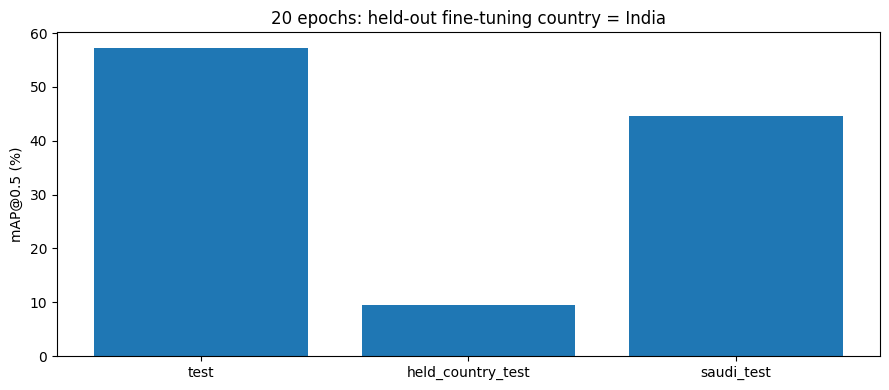

,requirement,status,evidence
0,E4 held-country and Saudi external test,completed,E4_domain_shift.csv
1,priority +/-20% sensitivity,completed,rf_small_512_noaug/priority_sensitivity_summar...
2,team-collected local photos,missing; Saudi public subset is not team-colle...,split_summary.csv
3,Saudi independent human label review,not confirmed,data_protocol.json
4,CPU inference latency,completed,all_cpu_latency.csv
5,live app end-to-end latency,not measured by this notebook; requires actual...,CPU timing covers the specified pipeline only


Results: /content/drive/MyDrive/RoadScan_20Epoch_Experiments/India_6f44f8600748
Download: /content/drive/MyDrive/RoadScan_20Epoch_Experiments/India_6f44f8600748_results.zip
Model checkpoints remain in their run folders; preserve them separately.


In [12]:
metrics=pd.DataFrame(ALL_METRICS);metrics.to_csv(RUN_ROOT/'all_detection_metrics.csv',index=False)
if CPU_METRICS:pd.DataFrame(CPU_METRICS).to_csv(RUN_ROOT/'all_cpu_latency.csv',index=False)
main=metrics[metrics.run=='rf_small_512_noaug']
reference=main[main.split=='test'].iloc[0]
shift=main[main.split.isin(['test','held_country_test','saudi_test','team_local_test'])].copy()
shift['mAP50_gap_from_ID_percentage_points']=100*(shift.mAP50-float(reference.mAP50))
shift.to_csv(RUN_ROOT/'E4_domain_shift.csv',index=False);display(shift)
fig,ax=plt.subplots(figsize=(9,4))
ax.bar(shift.split,100*shift.mAP50);ax.set(ylabel='mAP@0.5 (%)',title=f'20 epochs: held-out fine-tuning country = {HELD_OUT_COUNTRY}')
fig.tight_layout();fig.savefig(RUN_ROOT/'E4_domain_shift.png',dpi=150);plt.show();plt.close(fig)
status=[dict(requirement='E4 held-country and Saudi external test',status='completed',evidence='E4_domain_shift.csv'),
    dict(requirement='priority +/-20% sensitivity',status='completed',evidence='rf_small_512_noaug/priority_sensitivity_summary.csv'),
    dict(requirement='team-collected local photos',status='completed' if SPLITS['team_local_test'] else 'missing; Saudi public subset is not team-collected',evidence='split_summary.csv'),
    dict(requirement='Saudi independent human label review',status='confirmed by user setting' if SAUDI_LABELS_HUMAN_VERIFIED else 'not confirmed',evidence='data_protocol.json')]
if 'comparison' in globals():
    status.append(dict(requirement='E1 classifier vs detector',status='completed',evidence='E1_classifier_vs_detector.csv'))
    for tag,name in [('E2 input resolution','rf_small_640_noaug'),('E3 horizontal flip','rf_small_512_flip')]:
        subset=metrics[metrics.run.isin(['rf_small_512_noaug',name])].copy()
        filename=tag.split()[0]+'_comparison.csv'
        if tag.startswith('E2') and CPU_METRICS:
            subset=subset.merge(pd.DataFrame(CPU_METRICS)[['run','mean_model_seconds','p95_model_seconds']],on='run',how='left')
        subset.to_csv(RUN_ROOT/filename,index=False)
        status.append(dict(requirement=tag,status='completed',evidence=filename))
    status.append(dict(requirement='E5 duplicate embeddings',status=E5_STATUS,evidence='E5_duplicate_embeddings/status.json'))
status.append(dict(requirement='CPU inference latency',status='completed' if CPU_METRICS else 'not measured',evidence='all_cpu_latency.csv'))
status.append(dict(requirement='live app end-to-end latency',status='not measured by this notebook; requires actual app session',evidence='CPU timing covers the specified pipeline only'))
pd.DataFrame(status).to_csv(RUN_ROOT/'requirements_status.csv',index=False);display(pd.DataFrame(status))
save_json(RUN_ROOT/'results_summary.json',dict(completed_training_epochs=EPOCHS,held_out_country=HELD_OUT_COUNTRY,
    split_sha256=SPLIT_HASH,runs=metrics.run.unique().tolist(),metrics=metrics.to_dict('records'),requirements=status))
notes=['# RoadScan experiment interpretation', '',
    f'Held-out country: {HELD_OUT_COUNTRY}. All detector results use final non-EMA weights after exactly 20 completed epochs.',
    'The country is excluded from RoadScan fine-tuning and validation; its presence in original general-purpose pretraining is unknown.',
    'Thresholds are selected only on validation. Detection AP uses low-confidence raw predictions; P/R/F1 use the frozen operating threshold.',
    'E4: inspect E4_domain_shift.csv and per-class AP tables. Country differences combine scene, annotation and class-distribution differences; no causal isolation.',
    'Priority agreement compares the same heuristic applied to predicted and annotated boxes, not expert repair urgency.',
    'Saudi images are a public external subset with draft annotations unless independently human-verified. Team local set is separate.',
    'CPU measurements include the documented pipeline, not UI/network latency. One seed and one 20-epoch budget do not establish statistical significance.',
    'Scene group IDs and pHash are useful leakage screens, not proof of geographic independence. Review near_duplicate_pairs.csv.',
    'Horizontal flips preserve longitudinal/transverse orientation; vertical flips and 90-degree rotations are avoided because they distort road geometry or class semantics.']
if 'comparison' in globals():
    notes += ['E1: compare image-level AP and F1 on the same images; do not compare classifier AP directly to bounding-box mAP.',
        'E2: compare 512 vs 640 after separate 20-epoch training at each resolution; see CPU latency and per-class AP together.',
        'E3: compare no horizontal flip vs 50% horizontal flip; seed, resolution, split and all other settings match.',
        'E5: '+E5_STATUS+'. Do not claim duplicate retrieval accuracy from a single photo per defect.']
    for split in ['test','held_country_test','saudi_test','team_local_test']:
        part=comparison[comparison.split==split]
        if len(part)==2:
            clf=part[part.model=='ResNet18 classifier'].iloc[0]
            det=part[part.model=='RF-DETR detector (image presence)'].iloc[0]
            notes.append(f'E1 {split}: classifier image F1={clf.image_macro_F1:.4f}; detector image F1={det.image_macro_F1:.4f}; difference={100*(det.image_macro_F1-clf.image_macro_F1):+.2f} percentage points. Only the detector also returns locations.')
    for name,tag in [('rf_small_640_noaug','E2'),('rf_small_512_flip','E3')]:
        changed=metrics[(metrics.run==name)&(metrics.split=='test')].iloc[0]
        notes.append(f'{tag} in-distribution test: baseline mAP50={reference.mAP50:.4f}; changed mAP50={changed.mAP50:.4f}; difference={100*(changed.mAP50-reference.mAP50):+.2f} percentage points. Inspect validation and external splits before interpretation; this is one seed.')
(RUN_ROOT/'interpretation.md').write_text('\n\n'.join(notes),encoding='utf-8')
# Portable result package excludes image copies, prediction caches and model checkpoints to keep it small.
archive=RUN_ROOT.parent/(RUN_ROOT.name+'_results.zip')
with zipfile.ZipFile(archive,'w',zipfile.ZIP_DEFLATED) as z:
    for p in sorted(RUN_ROOT.rglob('*')):
        if not p.is_file() or any(x in p.parts for x in ['coco_trainval','predictions']):continue
        if p.suffix.lower() in {'.csv','.json','.png','.md','.txt'}:z.write(p,p.relative_to(RUN_ROOT))
print('Results:',RUN_ROOT)
print('Download:',archive)
print('Model checkpoints remain in their run folders; preserve them separately.')
